# 03 Models: LightGBM on history, then history + text

- What it does: tunes LightGBM on the history features (M1), embeds the previous inspection's comments with a pre-trained BERT-style encoder, tunes LightGBM on history + text (M2), and compares the two on 2023.
- Inputs: `data/processed/model_table.parquet`, the baseline predictions in `preds/`.
- Outputs: `preds/M1_lgbm_val.csv`, `preds/M2_lgbm_text_val.csv`, `data/processed/embeddings.npy`, `results/validation_results.csv`, `results/lgbm_grid_val.csv`, `results/feature_importance_val.csv`, `results/text_examples.md`, `results/selected_settings.json`, `results/figures/gains_curve_val.png`.

All tuning uses the validation year (2023). The test years (2024 onward) are not used anywhere in this notebook.

In [1]:
import sys
sys.path.insert(0, "..")

import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

from src import evaluate as E
from src import models as M
from src import text as T

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 180)

In [2]:
table = M.load_model_table("../data/processed/model_table.parquet")
is_train = (table["split"] == "train").to_numpy()
is_val = (table["split"] == "val").to_numpy()
train, val = table[is_train], table[is_val]
y_val = val[M.TARGET].to_numpy()
print(f"train {len(train):,} rows | validation {len(val):,} rows")
print("history features:", M.HISTORY_FEATURES)

train 35,872 rows | validation 5,521 rows
history features: ['prior_n', 'prior_n_3y', 'is_first', 'prior_fail_rate', 'prior_routine_fail_rate', 'last_fail', 'last_n_viol', 'last_n_lvl3', 'last_routine_fail', 'last_routine_n_viol', 'last_routine_n_lvl3', 'days_since_last', 'license_age_days', 'month', 'is_takeout', 'neighborhood', 'zip']


## 1. M1: LightGBM on history features

A small grid of 12 combinations. Each fit stops early when the validation AUC stops improving, so `n_estimators` is an upper limit and `best_iteration` is the number of trees actually used. We keep the combination with the best validation hit rate (`precision_at_k`).

In [3]:
print("grid:", M.LGBM_GRID)
grid_m1, params_m1 = M.grid_search_lgbm(train, val, M.HISTORY_FEATURES)
print("selected M1 settings:", params_m1)
grid_m1.round(4)

grid: {'num_leaves': [7, 15, 31], 'learning_rate': [0.02, 0.05], 'n_estimators': [100, 500]}


selected M1 settings: {'num_leaves': 7, 'learning_rate': 0.02, 'n_estimators': 346}


,num_leaves,learning_rate,n_estimators,best_iteration,auc,catch_at_k,precision_at_k,n
0,7,0.02,100,100,0.7768,0.3215,0.8967,5521
1,7,0.02,500,346,0.7838,0.3245,0.9049,5521
2,7,0.05,100,99,0.7827,0.3238,0.9031,5521
3,7,0.05,500,127,0.7833,0.3238,0.9031,5521
4,15,0.02,100,98,0.7783,0.3235,0.9022,5521
5,15,0.02,500,360,0.7823,0.3238,0.9031,5521
6,15,0.05,100,100,0.7815,0.3228,0.9004,5521
7,15,0.05,500,134,0.7819,0.3228,0.9004,5521
8,31,0.02,100,94,0.7780,0.3232,0.9013,5521
9,31,0.02,500,247,0.7804,0.3235,0.9022,5521


In [4]:
m1 = M.fit_lgbm(train, M.HISTORY_FEATURES, params_m1)
score_m1 = m1.predict_proba(val[M.HISTORY_FEATURES])[:, 1]
M.save_preds(val, score_m1, "../preds/M1_lgbm_val.csv")

importance_m1 = M.importance_table(m1, M.HISTORY_FEATURES, top=15)
importance_m1.round(3)

,feature,gain,share_of_gain
0,last_routine_n_viol,95315.385,0.401
1,prior_routine_fail_rate,49939.135,0.210
2,prior_fail_rate,25119.788,0.106
3,zip,23465.938,0.099
4,last_fail,18175.436,0.076
5,days_since_last,6734.115,0.028
6,license_age_days,5333.242,0.022
7,month,3976.031,0.017
8,prior_n,3570.401,0.015
9,prior_n_3y,3011.162,0.013


## 2. Text: embed the previous inspection's comments

The text for each inspection is `prior_comments`: what the inspector wrote at the **previous** visit. Comments from the inspection being predicted are never used.

The encoder is `sentence-transformers/all-MiniLM-L6-v2`, used frozen (no training). Each comment becomes the average of its token vectors (mean pooling over the attention mask), a vector of 384 numbers. Comments are cut at 256 tokens.

First we time 100 comments to estimate the full run.

In [5]:
has_text = (table["prior_comments"].str.strip() != "").to_numpy()
n_unique = table.loc[has_text, "prior_comments"].nunique()
sample = table.loc[has_text, "prior_comments"].sample(100, random_state=SEED).tolist()

T.embed_texts(sample[:8], verbose=False)      # warm-up, so the timing excludes loading the model
started = time.time()
T.embed_texts(sample, verbose=False)
seconds_per_100 = time.time() - started
print(f"device: {T.get_device()} | 100 comments in {seconds_per_100:.2f}s | "
      f"estimated full run for {n_unique:,} unique comments: {seconds_per_100 / 100 * n_unique / 60:.1f} minutes")

W1111 16:45:21.345000 74740 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

device: mps | 100 comments in 0.41s | estimated full run for 39,356 unique comments: 2.7 minutes


In [6]:
# Cached: the second run of this notebook loads the file instead of embedding again.
embeddings = T.embed_cached(table["inspection_id"], table["prior_comments"], cache_dir="../data/processed")
print("embeddings:", embeddings.shape, "| rows with comments:", int(has_text.sum()),
      "| rows without (zero vector):", int((~has_text).sum()))

Cache does not match the current texts, embedding again.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

  embedded 64 of 39,356 unique texts (0s)


  embedded 6,464 of 39,356 unique texts (1s)


  embedded 12,864 of 39,356 unique texts (3s)


  embedded 19,264 of 39,356 unique texts (6s)


  embedded 25,664 of 39,356 unique texts (10s)


  embedded 32,064 of 39,356 unique texts (16s)


  embedded 38,464 of 39,356 unique texts (25s)


Saved embeddings (58564, 384) to ../data/processed/embeddings.npy
embeddings: (58564, 384) | rows with comments: 40379 | rows without (zero vector): 18185


### PCA to 32 dimensions, fitted on training rows only

384 text columns would swamp the 12 history features, so we compress them to 32 principal components. The PCA is fitted on training rows that have comments, then applied to every row.

In [7]:
pca = T.fit_pca(embeddings, fit_mask=is_train & has_text)
print(f"variance kept by 32 components: {pca.explained_variance_ratio_.sum():.1%}")

table_text = T.add_text_features(table, embeddings, pca)
train_t, val_t = table_text[is_train], table_text[is_val]
FEATURES_M2 = M.HISTORY_FEATURES + T.TEXT_FEATURES
print(len(FEATURES_M2), "features for M2")

variance kept by 32 components: 59.8%
50 features for M2


## 3. M2: LightGBM on history + text

Same grid, same selection rule.

In [8]:
grid_m2, params_m2 = M.grid_search_lgbm(train_t, val_t, FEATURES_M2)
print("selected M2 settings:", params_m2)
grid_m2.round(4)

selected M2 settings: {'num_leaves': 31, 'learning_rate': 0.02, 'n_estimators': 93}


,num_leaves,learning_rate,n_estimators,best_iteration,auc,catch_at_k,precision_at_k,n
0,7,0.02,100,99,0.7775,0.3219,0.8976,5521
1,7,0.02,500,382,0.7845,0.3232,0.9013,5521
2,7,0.05,100,98,0.7833,0.3232,0.9013,5521
3,7,0.05,500,210,0.7844,0.3232,0.9013,5521
4,15,0.02,100,99,0.7795,0.3232,0.9013,5521
5,15,0.02,500,273,0.7827,0.3225,0.8995,5521
6,15,0.05,100,100,0.7829,0.3232,0.9013,5521
7,15,0.05,500,122,0.7831,0.3222,0.8986,5521
8,31,0.02,100,93,0.7791,0.3235,0.9022,5521
9,31,0.02,500,231,0.7811,0.3232,0.9013,5521


In [9]:
m2 = M.fit_lgbm(train_t, FEATURES_M2, params_m2)
score_m2 = m2.predict_proba(val_t[FEATURES_M2])[:, 1]
M.save_preds(val, score_m2, "../preds/M2_lgbm_text_val.csv")

importance_m2 = M.importance_table(m2, FEATURES_M2, top=15)
pd.concat([grid_m1.assign(model="M1_lgbm"), grid_m2.assign(model="M2_lgbm_text")]).to_csv(
    "../results/lgbm_grid_val.csv", index=False)
pd.concat([importance_m1.assign(model="M1_lgbm"), importance_m2.assign(model="M2_lgbm_text")]).to_csv(
    "../results/feature_importance_val.csv", index=False)
importance_m2.round(3)

,feature,gain,share_of_gain
0,last_routine_n_viol,100338.626,0.439
1,prior_routine_fail_rate,41392.787,0.181
2,prior_fail_rate,22055.716,0.096
3,zip,19013.216,0.083
4,last_fail,16911.115,0.074
5,days_since_last,5330.698,0.023
6,license_age_days,4716.090,0.021
7,month,3517.021,0.015
8,prior_n_3y,2339.162,0.010
9,prior_n,1836.390,0.008


## 4. Does text add value? (ablation on validation)

M1 and M2 differ only in the text features. The confidence intervals come from 500 bootstrap resamples of the validation inspections. For the difference, both models are scored on the same resamples.

In [10]:
ablation = E.results_table(y_val, {"M1_lgbm": score_m1, "M2_lgbm_text": score_m2})
print(ablation.round(3).to_string(index=False))

print("\nM2 minus M1, with 95% CI:")
text_verdict = {}
for metric in ["precision_at_k", "catch_at_k", "auc"]:
    diff = E.evaluate(y_val, score_m2)[metric] - E.evaluate(y_val, score_m1)[metric]
    lo, hi = E.bootstrap_diff_ci(y_val, score_m2, score_m1, metric)
    text_verdict[metric] = (diff, lo, hi)
    print(f"  {metric:15s} {diff:+.3f}  [{lo:+.3f}, {hi:+.3f}]")

diff, lo, hi = text_verdict["precision_at_k"]
if lo > 0:
    sentence = (f"Adding the previous inspection's comments raises the validation hit rate by {diff * 100:.1f} points "
                f"(95% CI {lo * 100:+.1f} to {hi * 100:+.1f}), more than sampling noise.")
elif hi < 0:
    sentence = (f"Adding the previous inspection's comments lowers the validation hit rate by {-diff * 100:.1f} points "
                f"(95% CI {lo * 100:+.1f} to {hi * 100:+.1f}).")
else:
    sentence = (f"Adding the previous inspection's comments changes the validation hit rate by {diff * 100:+.1f} points "
                f"(95% CI {lo * 100:+.1f} to {hi * 100:+.1f}), which is within sampling noise: "
                f"on this data the text adds no measurable value beyond the history features.")
print("\n" + sentence)

       model   auc  catch_at_k  precision_at_k    n  auc_lo  auc_hi  catch_at_k_lo  catch_at_k_hi  precision_at_k_lo  precision_at_k_hi
     M1_lgbm 0.784       0.324           0.905 5521   0.773   0.796          0.316          0.332              0.883              0.922
M2_lgbm_text 0.779       0.323           0.902 5521   0.768   0.791          0.316          0.331              0.882              0.918

M2 minus M1, with 95% CI:


  precision_at_k  -0.003  [-0.011, +0.006]


  catch_at_k      -0.001  [-0.004, +0.002]


  auc             -0.005  [-0.008, -0.002]

Adding the previous inspection's comments changes the validation hit rate by -0.3 points (95% CI -1.1 to +0.6), which is within sampling noise: on this data the text adds no measurable value beyond the history features.


## 5. Examples where the text changed the ranking

Three failed validation inspections that M2 placed in its riskiest 10% and M1 ranked much lower.

In [11]:
examples = val[["inspection_id", "neighborhood", "prior_comments", M.TARGET]].copy()
examples["m1_percentile"] = pd.Series(score_m1, index=val.index).rank(pct=True)
examples["m2_percentile"] = pd.Series(score_m2, index=val.index).rank(pct=True)
picked = (examples[(examples[M.TARGET] == 1) & (examples["m2_percentile"] >= 0.90)]
          .assign(jump=lambda d: d["m2_percentile"] - d["m1_percentile"])
          .sort_values("jump", ascending=False).head(3))

lines = ["# Failed inspections that the text model ranked much higher",
         "",
         "Validation year (2023). Each inspection failed. The text model (M2) placed it in its riskiest 10%, "
         "and the history-only model (M1) ranked it lower. The snippet is the inspector's comment from the "
         "previous visit, which is the only text the model sees. Personal details are masked.",
         ""]
for i, row in enumerate(picked.itertuples(), 1):
    snippet = " ".join(row.prior_comments.split())[:400]
    lines += [f"## Example {i} ({row.neighborhood})",
              "",
              f"- History-only model: riskier than {row.m1_percentile:.0%} of inspections",
              f"- History + text model: riskier than {row.m2_percentile:.0%} of inspections",
              "",
              f"> {snippet}...",
              ""]
open("../results/text_examples.md", "w").write("\n".join(lines))
print("\n".join(lines))

# Failed inspections that the text model ranked much higher

Validation year (2023). Each inspection failed. The text model (M2) placed it in its riskiest 10%, and the history-only model (M1) ranked it lower. The snippet is the inspector's comment from the previous visit, which is the only text the model sees. Personal details are masked.

## Example 1 (Brighton)

- History-only model: riskier than 84% of inspections
- History + text model: riskier than 94% of inspections

> Wash cycle of high temperature dish machine not reaching proper temperature after multiple attempts. Provide service call. | Quat sanitizer from dispenser at three bay sink testing at 0ppm. Person in charge indicated they are out of quat sanitizer. Bleach on site and being used for sanitizer until quat sanitizer is ordered. | No chlorine test strips available for bleach sanitizer. Tested with insp...

## Example 2 (Boston)

- History-only model: riskier than 82% of inspections
- History + text model: riskier than 9

## 6. All five models on validation

In [12]:
val_scores = {name: pd.read_csv(f"../preds/{name}_val.csv")["score"].to_numpy()
              for name in ["B0_random", "B1_past_fail_rate", "B2_logreg"]}
val_scores["M1_lgbm"] = score_m1
val_scores["M2_lgbm_text"] = score_m2

validation_results = E.results_table(y_val, val_scores)
validation_results.to_csv("../results/validation_results.csv", index=False)
validation_results.round(3)

,model,auc,catch_at_k,precision_at_k,n,auc_lo,auc_hi,catch_at_k_lo,catch_at_k_hi,precision_at_k_lo,precision_at_k_hi
0,B0_random,0.503,0.204,0.569,5521,0.488,0.518,0.195,0.213,0.541,0.594
1,B1_past_fail_rate,0.677,0.247,0.689,5521,0.663,0.691,0.237,0.256,0.660,0.716
2,B2_logreg,0.776,0.319,0.889,5521,0.764,0.789,0.311,0.327,0.870,0.907
3,M1_lgbm,0.784,0.324,0.905,5521,0.773,0.796,0.316,0.332,0.883,0.922
4,M2_lgbm_text,0.779,0.323,0.902,5521,0.768,0.791,0.316,0.331,0.882,0.918


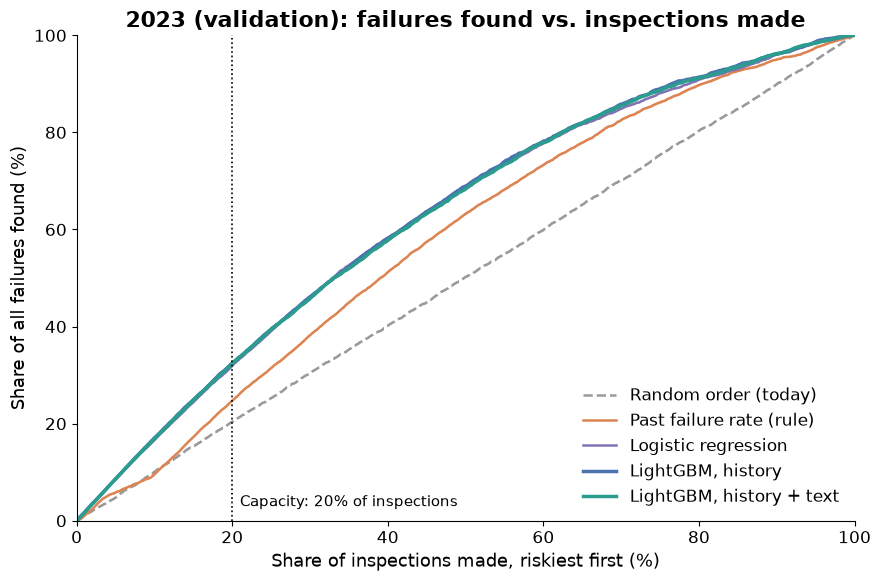

In [13]:
fig = E.plot_gains(y_val, val_scores, "2023 (validation): failures found vs. inspections made",
                   path="../results/figures/gains_curve_val.png")
plt.show()

## 7. Save the selected settings

These are the settings chosen on validation. They are copied to `docs/FROZEN_CONFIG.json` at the freeze commit, and notebook 04 reads that frozen file.

In [14]:
selected = {
    "seed": SEED,
    "capacity_k": E.K,
    "selection_metric": "precision_at_k on validation (2023)",
    "history_features": M.HISTORY_FEATURES,
    "B0_random": {"seed": SEED},
    "B1_past_fail_rate": {"first_inspection_fallback": "base rate of the fitting data"},
    "B2_logreg": {"pipeline": "median impute with missing flags -> standard scale -> LogisticRegression(max_iter=2000)"},
    "M1_lgbm": {"features": "history", **params_m1},
    "M2_lgbm_text": {"features": "history + 32 text PCs + has_prior_comments", **params_m2,
                     "encoder": T.MODEL_NAME, "max_tokens": T.MAX_TOKENS, "pooling": "mean over attention mask",
                     "pca_components": T.N_COMPONENTS},
    "lgbm_fixed": {k: v for k, v in M.LGBM_FIXED.items()},
}
json.dump(selected, open("../results/selected_settings.json", "w"), indent=2)
print(json.dumps(selected, indent=2))

{
  "seed": 42,
  "capacity_k": 0.2,
  "selection_metric": "precision_at_k on validation (2023)",
  "history_features": [
    "prior_n",
    "prior_n_3y",
    "is_first",
    "prior_fail_rate",
    "prior_routine_fail_rate",
    "last_fail",
    "last_n_viol",
    "last_n_lvl3",
    "last_routine_fail",
    "last_routine_n_viol",
    "last_routine_n_lvl3",
    "days_since_last",
    "license_age_days",
    "month",
    "is_takeout",
    "neighborhood",
    "zip"
  ],
  "B0_random": {
    "seed": 42
  },
  "B1_past_fail_rate": {
    "first_inspection_fallback": "base rate of the fitting data"
  },
  "B2_logreg": {
    "pipeline": "median impute with missing flags -> standard scale -> LogisticRegression(max_iter=2000)"
  },
  "M1_lgbm": {
    "features": "history",
    "num_leaves": 7,
    "learning_rate": 0.02,
    "n_estimators": 346
  },
  "M2_lgbm_text": {
    "features": "history + 32 text PCs + has_prior_comments",
    "num_leaves": 31,
    "learning_rate": 0.02,
    "n_estimators"